# Analogizer learner: support vector regression with a kernel

## Preprocessing

In [1]:
import numpy as np
import polars as pl
from sklearn.metrics import mean_absolute_error, r2_score, root_mean_squared_error
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.preprocessing import StandardScaler

SEED = 42
FEATURES = [
    "length", "diameter", "height", "whole_weight", "shucked_weight", "viscera_weight", "shell_weight",
    "is_infant", "is_female",
]

# cleaning and sex encoding (fixed rules, before the split)
df = pl.read_csv("./data/abalone.csv.zst")
df = df.filter(~((pl.col("height") == 0) | (pl.col("height") > 0.3)))
df = df.with_columns(
    is_infant=(pl.col("sex") == "I").cast(pl.Int8),
    is_female=(pl.col("sex") == "F").cast(pl.Int8),
).drop("sex")

# 20% hold-out test (not used until the end) and 5 stratified folds on the development part
rings_all = df["rings"].to_numpy()
y_bins = np.digitize(rings_all, np.quantile(rings_all, [0.2, 0.4, 0.6, 0.8]))
dev_idx, test_idx = train_test_split(np.arange(df.height), test_size=0.2, random_state=SEED, stratify=y_bins)
dev, test = df[dev_idx], df[test_idx]
X, rings = dev.select(FEATURES).to_numpy(), dev["rings"].to_numpy()
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED).split(X, y_bins[dev_idx]))


def cross_validate(fit_predict, verbose=True):
    """fit_predict(X_train, y_train, X_val) -> predictions. Standardization is fitted on each training part."""
    scores = []
    for tr, va in folds:
        scaler = StandardScaler().fit(X[tr])
        pred = fit_predict(scaler.transform(X[tr]), rings[tr], scaler.transform(X[va]))
        scores.append((root_mean_squared_error(rings[va], pred), mean_absolute_error(rings[va], pred), r2_score(rings[va], pred)))
    scores = np.array(scores)
    m, sd = scores.mean(axis=0), scores.std(axis=0, ddof=1)
    if verbose:
        print(f"RMSE {m[0]:.3f} ± {sd[0]:.3f}   MAE {m[1]:.3f} ± {sd[1]:.3f}   R² {m[2]:.3f} ± {sd[2]:.3f}")
    return scores


baseline = cross_validate(lambda X_tr, y_tr, X_va: np.full(len(X_va), y_tr.mean()))

RMSE 3.226 ± 0.159   MAE 2.366 ± 0.084   R² -0.001 ± 0.001


## Model: support vector regression (SVR) with an RBF kernel

An analogizer predicts a new animal by **comparing it with similar animals** it has already seen. The similarity is called the kernel. Here it is the RBF kernel: close to 1 for animals with almost the same measurements, and close to 0 for very different ones.

The prediction is a weighted sum of the similarities between the new animal and the **support vectors**. These are the training animals the model decided to keep, and all the others are ignored. The same data always gives the same model, because there is no random start.

Three hyper-parameters control it:

* **`ε` (epsilon):** errors smaller than `ε` are ignored. The wider this tolerance, the fewer animals the model needs to keep, so it is simpler.
* **`C`:** how much a bigger error costs. A small `C` gives a smooth, stiff model. A large `C` tries to fit every training animal, noise included.
* **`γ` (gamma):** how far the similarity reaches. A small `γ` means even distant animals count as similar, which gives a smooth, almost straight model. A large `γ` means only very close animals count, which gives a wiggly model.

The features and `rings` are standardized (mean 0, standard deviation 1, fitted on the training part). The RBF kernel compares animals by distance, so features on different scales would distort it. Standardizing `rings` also means `ε` is measured in standard deviations of `rings`.

In [2]:
from sklearn.svm import SVR


def svr(X_tr, y_tr, X_va, kernel="rbf", C=1.0, gamma=0.1, epsilon=0.1, n_sv=None):
    mu, sd = y_tr.mean(), y_tr.std()
    model = SVR(kernel=kernel, C=C, gamma=gamma, epsilon=epsilon).fit(X_tr, (y_tr - mu) / sd)
    if n_sv is not None:
        n_sv.append(len(model.support_))
    return model.predict(X_va) * sd + mu


analogizer = cross_validate(svr)

RMSE 2.133 ± 0.095   MAE 1.467 ± 0.016   R² 0.562 ± 0.017


### Tuning

Hyper-parameters are chosen on the 5 validation folds only. Among the configurations whose mean RMSE is within one standard error of the best one (`std / √5` of the best), the **simplest** is chosen: the one with the fewest support vectors (the size of an SVR is the number of training animals it keeps), and the lowest mean RMSE if several have the same size.

| Hyper-parameter | Values | Why |
|---|---|---|
| `C` | 0.3, 1, 3, 10 | price of an error outside the tube: stiff against flexible |
| `gamma` | 0.01, 0.03, 0.1, 0.3 | reach of the similarity. With 9 standardized features, `1/9 ≈ 0.11` is the usual scale |
| `epsilon` | 0.05, 0.2, 0.5 | half-width of the tube, in standard deviations of `rings` |

Fixed: RBF kernel, standardized features and target. The 4 × 4 × 3 = 48 combinations are a **grid search**: all of them are tried, each one scored with the same 5 folds. The grid is log-spaced because `C` and `γ` act on a multiplicative scale.

In [3]:
from itertools import product

results = []
for C, gamma, epsilon in product([0.3, 1, 3, 10], [0.01, 0.03, 0.1, 0.3], [0.05, 0.2, 0.5]):
    n_sv = []
    scores = cross_validate(lambda X_tr, y_tr, X_va: svr(X_tr, y_tr, X_va, C=C, gamma=gamma, epsilon=epsilon, n_sv=n_sv), verbose=False)
    results.append((C, gamma, epsilon, np.mean(n_sv), scores[:, 0].mean(), scores[:, 0].std(ddof=1)))

tuning = pl.DataFrame(results, schema=["C", "gamma", "epsilon", "support vectors", "mean RMSE", "std RMSE"], orient="row").sort("mean RMSE")

with pl.Config(tbl_rows=10):
    print(tuning)
top = tuning.row(0, named=True)
limit = top["mean RMSE"] + top["std RMSE"] / np.sqrt(len(folds))
best = tuning.filter(pl.col("mean RMSE") <= limit).sort(["support vectors", "mean RMSE"]).row(0, named=True)
print("lowest mean RMSE:", {k: top[k] for k in ['C', 'gamma', 'epsilon', 'support vectors']}, f"RMSE {top['mean RMSE']:.3f}")
print("simplest within one standard error:", {k: best[k] for k in ['C', 'gamma', 'epsilon', 'support vectors']}, f"RMSE {best['mean RMSE']:.3f}, limit {limit:.3f}")

shape: (48, 6)
┌──────┬───────┬─────────┬─────────────────┬───────────┬──────────┐
│ C    ┆ gamma ┆ epsilon ┆ support vectors ┆ mean RMSE ┆ std RMSE │
│ ---  ┆ ---   ┆ ---     ┆ ---             ┆ ---       ┆ ---      │
│ f64  ┆ f64   ┆ f64     ┆ f64             ┆ f64       ┆ f64      │
╞══════╪═══════╪═════════╪═════════════════╪═══════════╪══════════╡
│ 10.0 ┆ 0.03  ┆ 0.5     ┆ 895.8           ┆ 2.099168  ┆ 0.095303 │
│ 10.0 ┆ 0.1   ┆ 0.5     ┆ 887.2           ┆ 2.10131   ┆ 0.086834 │
│ 3.0  ┆ 0.1   ┆ 0.5     ┆ 889.4           ┆ 2.101653  ┆ 0.082726 │
│ 10.0 ┆ 0.03  ┆ 0.2     ┆ 1751.8          ┆ 2.109022  ┆ 0.098408 │
│ 3.0  ┆ 0.03  ┆ 0.5     ┆ 903.6           ┆ 2.112554  ┆ 0.090088 │
│ …    ┆ …     ┆ …       ┆ …               ┆ …         ┆ …        │
│ 0.3  ┆ 0.03  ┆ 0.2     ┆ 1773.0          ┆ 2.223654  ┆ 0.099895 │
│ 0.3  ┆ 0.03  ┆ 0.05    ┆ 2442.6          ┆ 2.224075  ┆ 0.099509 │
│ 0.3  ┆ 0.01  ┆ 0.5     ┆ 959.2           ┆ 2.289646  ┆ 0.109784 │
│ 0.3  ┆ 0.01  ┆ 0.2     ┆ 1794.6

### What the kernel buys

The same SVR with a **linear** kernel (`k(x, x') = x · x'`) is a linear model, like OLS, so the difference to the RBF kernel is the gain from comparing animals by similarity instead of by a straight line. The `C` and `epsilon` are the chosen ones; `gamma` does not exist for the linear kernel.

In [4]:
print("linear kernel:  ", end="")
linear = cross_validate(lambda X_tr, y_tr, X_va: svr(X_tr, y_tr, X_va, kernel="linear", C=best["C"], epsilon=best["epsilon"]))
print("RBF kernel:     ", end="")
rbf = cross_validate(lambda X_tr, y_tr, X_va: svr(X_tr, y_tr, X_va, C=best["C"], gamma=best["gamma"], epsilon=best["epsilon"]))

linear kernel:  

RMSE 2.190 ± 0.075   MAE 1.565 ± 0.019   R² 0.538 ± 0.026
RBF kernel:     

RMSE 2.101 ± 0.087   MAE 1.494 ± 0.023   R² 0.575 ± 0.027


## Final evaluation on the test set

The chosen hyper-parameters (simplest within one standard error of the best) are used to refit the model on the **whole development part** (3338 rows), and the model is scored **once** on the 20% test set (835 rows). Nothing is chosen from the test result.

baseline   test RMSE 3.207   MAE 2.351   R² -0.000


SVR        test RMSE 2.154   MAE 1.500   R² 0.549


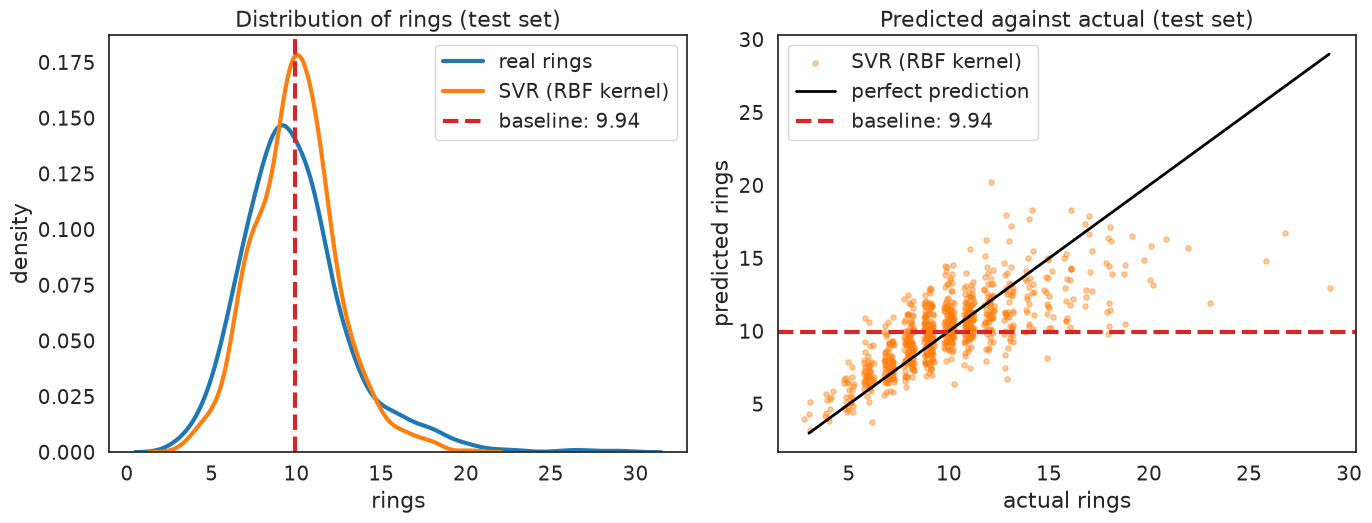

In [5]:
from pathlib import Path
import matplotlib.pyplot as plt
import seaborn as sns

def test_evaluate(name, fit_predict):
    """Refit on the whole development part (standardized with its own mean and sd) and score once on the test set."""
    scaler = StandardScaler().fit(X)
    y = test["rings"].to_numpy()
    pred = fit_predict(scaler.transform(X), rings, scaler.transform(test.select(FEATURES).to_numpy()))
    print(f"{name:10s} test RMSE {root_mean_squared_error(y, pred):.3f}   MAE {mean_absolute_error(y, pred):.3f}   R² {r2_score(y, pred):.3f}")
    return pred


def plot_test(pred, name):
    """Left: distribution of the real rings, of the predictions and of the baseline. Right: predicted against actual."""
    y_test, base = test["rings"].to_numpy(), rings.mean()
    jitter = np.random.default_rng(SEED).uniform(-0.25, 0.25, len(y_test))  # rings are integers: spread the dots sideways
    with sns.axes_style("white"), sns.plotting_context("notebook", font_scale=1.3):
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.5))
        sns.kdeplot(y_test, ax=ax1, lw=3, color="C0", label="real rings")
        sns.kdeplot(pred, ax=ax1, lw=3, color="C1", label=name)
        ax1.axvline(base, color="C3", lw=3, ls="--", label=f"baseline: {base:.2f}")
        ax1.set(title="Distribution of rings (test set)", xlabel="rings", ylabel="density")
        ax1.legend()
        ax2.scatter(y_test + jitter, pred, s=14, alpha=0.4, color="C1", label=name)
        ax2.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], color="k", lw=2, label="perfect prediction")
        ax2.axhline(base, color="C3", lw=3, ls="--", label=f"baseline: {base:.2f}")
        ax2.set(title="Predicted against actual (test set)", xlabel="actual rings", ylabel="predicted rings")
        ax2.legend()
        plt.tight_layout()
        plt.show()


test_evaluate("baseline", lambda X_tr, y_tr, X_va: np.full(len(X_va), y_tr.mean()))
final = lambda X_tr, y_tr, X_va: svr(X_tr, y_tr, X_va, C=best["C"], gamma=best["gamma"], epsilon=best["epsilon"])
pred = test_evaluate("SVR", final)
plot_test(pred, "SVR (RBF kernel)")

# validation scores of the chosen model and its test predictions, for the comparison in evaluation.ipynb
val = cross_validate(final, verbose=False)
Path("results").mkdir(exist_ok=True)
np.savez("results/analogizers.npz", val_rmse=val[:, 0], baseline_rmse=baseline[:, 0], test_y=test["rings"].to_numpy(), test_pred=pred)